<a href="https://colab.research.google.com/github/MAI-AIIU/deep-learning/blob/main/src/eighth-week/dropout.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Metadata
**Name**  
> Naveed Ahmad Hematmal

**Assignment**    

> Image Classification dataset

# Dropout
:label:`sec_dropout`


Let's think briefly about what we
expect from a good predictive model.
We want it to peform well on unseen data.
Classical generalization theory
suggests that to close the gap between
train and test performance,
we should aim for a simple model.
Simplicity can come in the form
of a small number of dimensions.
We explored this when discussing the
monomial basis functions of linear models
in :numref:`sec_generalization_basics`.
Additionally, as we saw when discussing weight decay
($\ell_2$ regularization) in :numref:`sec_weight_decay`,
the (inverse) norm of the parameters also
represents a useful measure of simplicity.
Another useful notion of simplicity is smoothness,
i.e., that the function should not be sensitive
to small changes to its inputs.
For instance, when we classify images,
we would expect that adding some random noise
to the pixels should be mostly harmless.

:citet:`Bishop.1995` formalized
this idea when he proved that training with input noise
is equivalent to Tikhonov regularization.
This work drew a clear mathematical connection
between the requirement that a function be smooth (and thus simple),
and the requirement that it be resilient
to perturbations in the input.

Then, :citet:`Srivastava.Hinton.Krizhevsky.ea.2014`
developed a clever idea for how to apply Bishop's idea
to the internal layers of a network, too.
Their idea, called *dropout*, involves
injecting noise while computing
each internal layer during forward propagation,
and it has become a standard technique
for training neural networks.
The method is called *dropout* because we literally
*drop out* some neurons during training.
Throughout training, on each iteration,
standard dropout consists of zeroing out
some fraction of the nodes in each layer
before calculating the subsequent layer.

To be clear, we are imposing
our own narrative with the link to Bishop.
The original paper on dropout
offers intuition through a surprising
analogy to sexual reproduction.
The authors argue that neural network overfitting
is characterized by a state in which
each layer relies on a specific
pattern of activations in the previous layer,
calling this condition *co-adaptation*.
Dropout, they claim, breaks up co-adaptation
just as sexual reproduction is argued to
break up co-adapted genes.
While such an justification of this theory is certainly up for debate,
the dropout technique itself has proved enduring,
and various forms of dropout are implemented
in most deep learning libraries.


The key challenge is how to inject this noise.
One idea is to inject it in an *unbiased* manner
so that the expected value of each layer---while fixing
the others---equals the value it would have taken absent noise.
In Bishop's work, he added Gaussian noise
to the inputs to a linear model.
At each training iteration, he added noise
sampled from a distribution with mean zero
$\epsilon \sim \mathcal{N}(0,\sigma^2)$ to the input $\mathbf{x}$,
yielding a perturbed point $\mathbf{x}' = \mathbf{x} + \epsilon$.
In expectation, $E[\mathbf{x}'] = \mathbf{x}$.

In standard dropout regularization,
one zeros out some fraction of the nodes in each layer
and then *debiases* each layer by normalizing
by the fraction of nodes that were retained (not dropped out).
In other words,
with *dropout probability* $p$,
each intermediate activation $h$ is replaced by
a random variable $h'$ as follows:

$$
\begin{aligned}
h' =
\begin{cases}
    0 & \textrm{ with probability } p \\
    \frac{h}{1-p} & \textrm{ otherwise}
\end{cases}
\end{aligned}
$$

By design, the expectation remains unchanged, i.e., $E[h'] = h$.


In [52]:
import random

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

random.seed(0)
torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Dropout in Practice

Applying dropout to a hidden layer can be viewed as training a network that uses a randomly selected subset of the hidden units on each iteration. The removed units contribute neither to the next layer nor to the gradient for that iteration.

![MLP before and after dropout.](https://github.com/MAI-AIIU/deep-learning/blob/main/src/img/dropout2.svg?raw=1)
:label:`fig_dropout2`

With inverted dropout, the surviving activations are scaled during training, so dropout can be disabled at evaluation time without further normalization. PyTorch modules switch this behavior automatically between `model.train()` and `model.eval()`. One optional variant, often called Monte Carlo dropout, keeps dropout active for repeated predictions as a rough uncertainty estimate.

In [53]:
def dropout_layer(X, dropout):
    if not 0.0 <= dropout <= 1.0:
        raise ValueError("dropout must be between 0 and 1")
    if dropout == 1.0:
        return torch.zeros_like(X)
    if dropout == 0.0:
        return X
    keep_mask = (torch.rand_like(X) >= dropout).to(X.dtype)
    return keep_mask * X / (1.0 - dropout)

We can [**test out the `dropout_layer` function on a few examples**].
In the following lines of code,
we pass our input `X` through the dropout operation,
with probabilities 0, 0.5, and 1, respectively.


In [54]:
X = torch.arange(16, dtype = torch.float32).reshape((2, 8))
print('original_x = ', X)
print('dropout_p = 0:', dropout_layer(X, 0))
print('dropout_p = 0.5:', dropout_layer(X, 0.5))
print('dropout_p = 1:', dropout_layer(X, 1))

original_x =  tensor([[ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11., 12., 13., 14., 15.]])
dropout_p = 0: tensor([[ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11., 12., 13., 14., 15.]])
dropout_p = 0.5: tensor([[ 0.,  2.,  0.,  0.,  0., 10.,  0., 14.],
        [ 0., 18.,  0.,  0.,  0.,  0.,  0., 30.]])
dropout_p = 1: tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])


### Defining the Model

The scratch model applies dropout after each hidden layer's activation. Each layer can have its own dropout probability. The custom implementation is called only while the model is training, and evaluation mode leaves activations unchanged.

In [55]:
class DropoutMLPScratch(nn.Module):
    def __init__(
        self,
        num_outputs=10,
        num_hiddens_1=256,
        num_hiddens_2=256,
        dropout_1=0.2,
        dropout_2=0.5,
    ):
        super().__init__()
        self.dropout_1 = dropout_1
        self.dropout_2 = dropout_2
        self.lin1 = nn.Linear(28 * 28, num_hiddens_1)
        self.lin2 = nn.Linear(num_hiddens_1, num_hiddens_2)
        self.lin3 = nn.Linear(num_hiddens_2, num_outputs)

        # those below lines are added to track variance for exercise 3
        # self.variances_before = []
        # self.variances_after = []

    # def forward(self, X):
    #     hidden_1 = F.relu(self.lin1(X.reshape(X.shape[0], -1)))
    #     # those below lines are added to track variance for exercise 3
    #     # self.variances_before.append(hidden_1.var().item())
    #     if self.training:
    #         hidden_1 = dropout_layer(hidden_1, self.dropout_1)

    #         # those below lines are added to track variance for exercise 3
    #         # self.variances_after.append(hidden_1.var().item())
    #     hidden_2 = F.relu(self.lin2(hidden_1))
    #     if self.training:
    #         hidden_2 = dropout_layer(hidden_2, self.dropout_2)
    #     return self.lin3(hidden_2)

    # this function is added to check how dropout works with weights which is called DropConnect, and is done for exercise 5.
    def forward(self, X):
      X = X.reshape(X.shape[0], -1)

      if self.training:
          w1 = dropout_layer(self.lin1.weight, self.dropout_1)
          w2 = dropout_layer(self.lin2.weight, self.dropout_2)
      else:
          w1 = self.lin1.weight
          w2 = self.lin2.weight

      hidden_1 = F.relu(F.linear(X, w1, self.lin1.bias))
      hidden_2 = F.relu(F.linear(hidden_1, w2, self.lin2.bias))

      return self.lin3(hidden_2)

### Training

We load Fashion-MNIST with `torchvision` and use native PyTorch data loaders. A shared loop trains both models with cross-entropy and SGD, then reports train and test loss and accuracy.

In [56]:
batch_size = 256
num_epochs = 3
# the number of epochs increased for exercise 2
# num_epochs = 20
learning_rate = 0.1

transform = transforms.ToTensor()
train_dataset = datasets.FashionMNIST(root="../data", train=True, transform=transform, download=True)
test_dataset = datasets.FashionMNIST(root="../data", train=False, transform=transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)


def evaluate(model, data_loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    with torch.no_grad():
        for images, targets in data_loader:
            images, targets = images.to(device), targets.to(device)
            logits = model(images)
            total_loss += F.cross_entropy(logits, targets, reduction="sum").item()
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_examples += targets.shape[0]
    return total_loss / total_examples, total_correct / total_examples


def train_model(model, train_loader, test_loader, epochs=10, lr=0.1, weight_decay=0.0):
    model = model.to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "train_accuracy": [], "test_loss": [], "test_accuracy": []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_correct = 0
        total_examples = 0
        for images, targets in train_loader:
            images, targets = images.to(device), targets.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = F.cross_entropy(logits, targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * targets.shape[0]
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_examples += targets.shape[0]

        train_loss = total_loss / total_examples
        train_accuracy = total_correct / total_examples
        test_loss, test_accuracy = evaluate(model, test_loader)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_accuracy)
        print(
            f"Epoch {epoch + 1:2d}/{epochs} | "
            f"train loss {train_loss:.4f}, accuracy {train_accuracy:.2%} | "
            f"test loss {test_loss:.4f}, accuracy {test_accuracy:.2%}"
        )

        # Those below lines are added to track variance for exercise 3
        # print(f"Before dropout: {sum(model.variances_before) / len(model.variances_before):.4f}")
        # print(f"After dropout:  {sum(model.variances_after) / len(model.variances_after):.4f}")

        # model.variances_before.clear()
        # model.variances_after.clear()
    return history


# hparams = {
#     "num_outputs": 10,
#     "num_hiddens_1": 256,
#     "num_hiddens_2": 256,
#     "dropout_1": 0.2,
#     "dropout_2": 0.5,
# }

# 1. Those are hparams are for 1 Exercise question
hparams = {
    "num_outputs": 10,
    "num_hiddens_1": 256,
    "num_hiddens_2": 256,
    "dropout_1": 0.5,
    "dropout_2": 0.2,
}

# 2. Those are hparams are for 2 Exercise question where dropout is zero, but the epochs will increase
# hparams = {
#     "num_outputs": 10,
#     "num_hiddens_1": 256,
#     "num_hiddens_2": 256,
#     "dropout_1": 0,
#     "dropout_2": 0,
# }

scratch_model = DropoutMLPScratch(**hparams)
scratch_history = train_model(
    scratch_model, train_loader, test_loader, epochs=num_epochs, lr=learning_rate
)

Epoch  1/3 | train loss 1.0898, accuracy 60.58% | test loss 0.6965, accuracy 73.30%
Epoch  2/3 | train loss 0.6258, accuracy 77.37% | test loss 0.6023, accuracy 78.07%
Epoch  3/3 | train loss 0.5377, accuracy 80.69% | test loss 0.5106, accuracy 82.00%


## Concise Implementation

PyTorch's built-in `nn.Dropout` performs inverted dropout during training and becomes an identity operation in evaluation mode. We use the same architecture, data, and training loop as the scratch implementation so their results can be compared.

In [57]:
class DropoutMLP(nn.Module):
    def __init__(
        self,
        num_outputs=10,
        num_hiddens_1=256,
        num_hiddens_2=256,
        dropout_1=0.2,
        dropout_2=0.5,
    ):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, num_hiddens_1),
            nn.ReLU(),
            nn.Dropout(dropout_1),
            nn.Linear(num_hiddens_1, num_hiddens_2),
            nn.ReLU(),
            nn.Dropout(dropout_2),
            nn.Linear(num_hiddens_2, num_outputs),
        )

    def forward(self, X):
        return self.net(X)

Train the concise model and compare its test metrics with those of the custom dropout implementation.

Epoch  1/3 | train loss 1.1013, accuracy 60.99% | test loss 0.6735, accuracy 75.84%
Epoch  2/3 | train loss 0.6473, accuracy 76.76% | test loss 0.5523, accuracy 79.87%
Epoch  3/3 | train loss 0.5490, accuracy 80.66% | test loss 0.5054, accuracy 81.67%


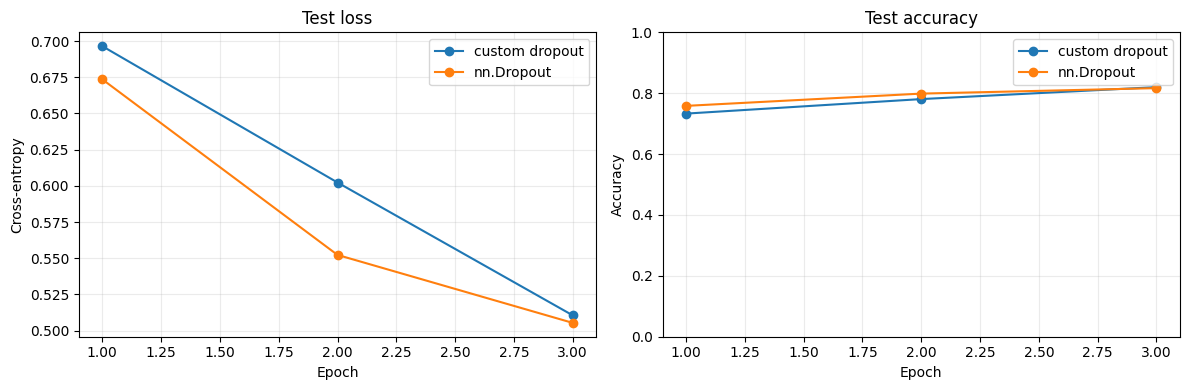

In [58]:
concise_model = DropoutMLP(**hparams)
concise_history = train_model(
    concise_model, train_loader, test_loader, epochs=num_epochs, lr=learning_rate
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, num_epochs + 1)
for history, label in ((scratch_history, "custom dropout"), (concise_history, "nn.Dropout")):
    axes[0].plot(epochs, history["test_loss"], marker="o", label=label)
    axes[1].plot(epochs, history["test_accuracy"], marker="o", label=label)
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy", title="Test loss")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Test accuracy", ylim=(0, 1))
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
plt.tight_layout()
plt.show()

## Summary

Dropout is a regularization technique that randomly masks activations during training and rescales the retained values so their expected value is preserved. We implemented it directly with PyTorch tensor operations and compared that implementation with `nn.Dropout`. Both models use native PyTorch modules, autograd, data loaders, SGD, and cross-entropy loss.

## Exercises

1. Change the dropout probabilities for the first and second layers, including swapping their values. Compare the test metrics.
2. Increase the number of epochs and compare dropout against a model with both dropout probabilities set to zero.
3. Measure the variance of hidden activations with and without dropout. How does it change during training?
<!-- 1. Why is dropout usually disabled during evaluation? -->
4. Compare dropout with weight decay, both separately and together.
5. What might happen if dropout were applied to weights instead of activations?
<!-- 1. Propose another way to inject noise during training and compare it with dropout on Fashion-MNIST.

**Setup:** Requires PyTorch, torchvision, and matplotlib. Fashion-MNIST downloads into `../data` on first use. -->

## Solutions

#### 1. Change the dropout probabilities for the first and second layers, including swapping their values. Compare the test metrics.

For the first values it was
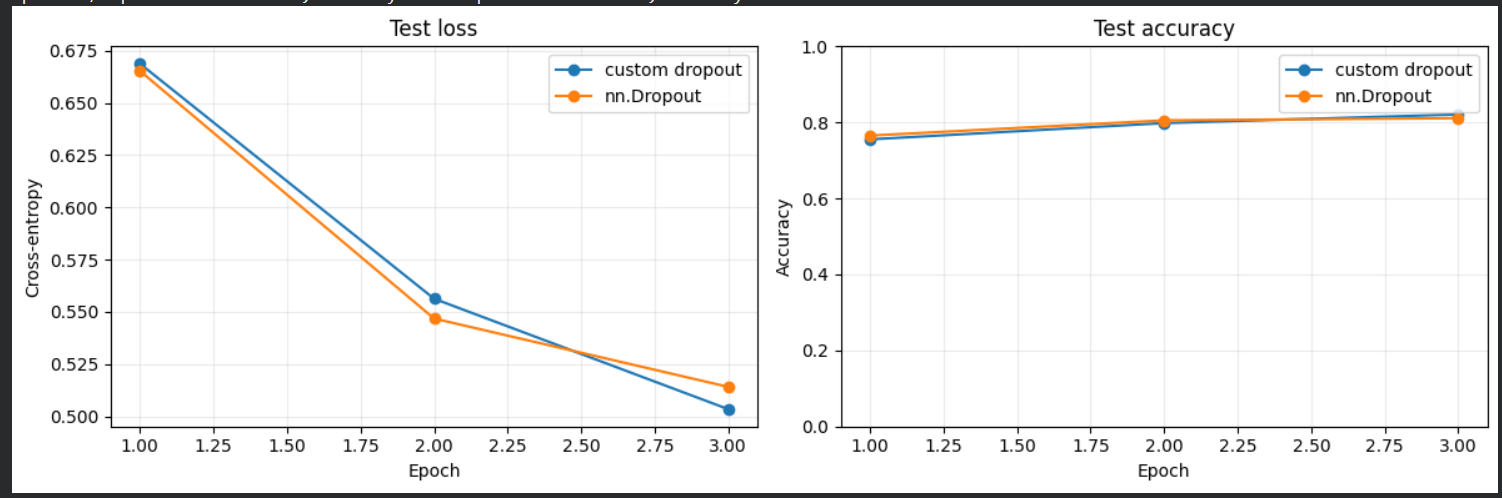


While swapping the values it become
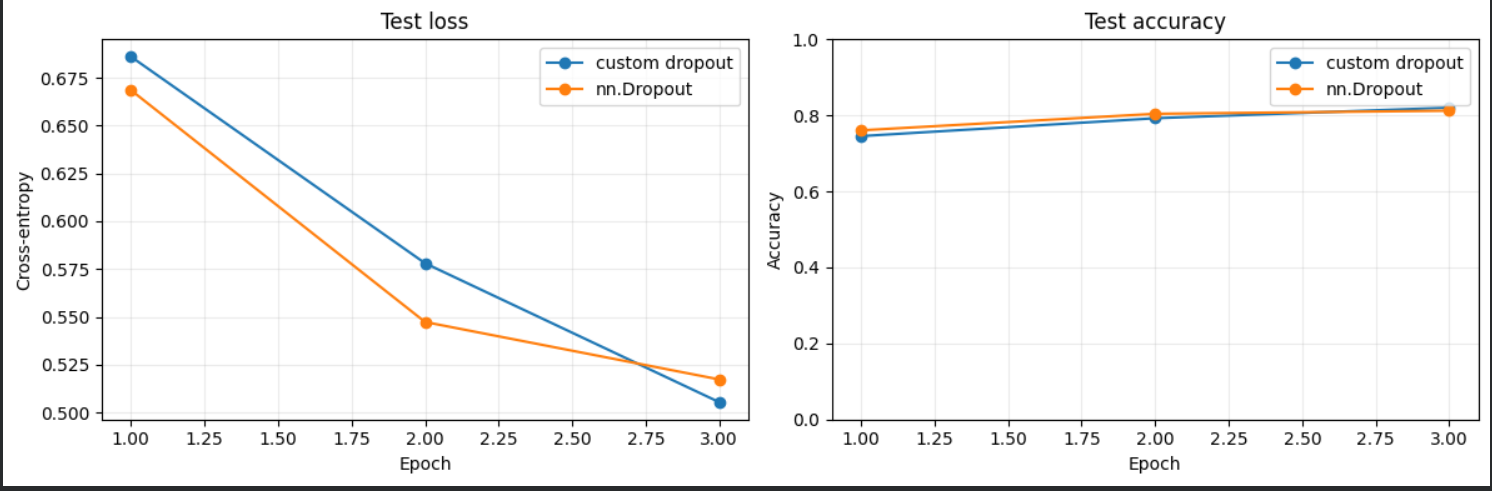

#### 2. Increase the number of epochs and compare dropout against a model with both dropout probabilities set to zero.

This image shows having dropouts (0.5, 0.2) with only 3 epochs

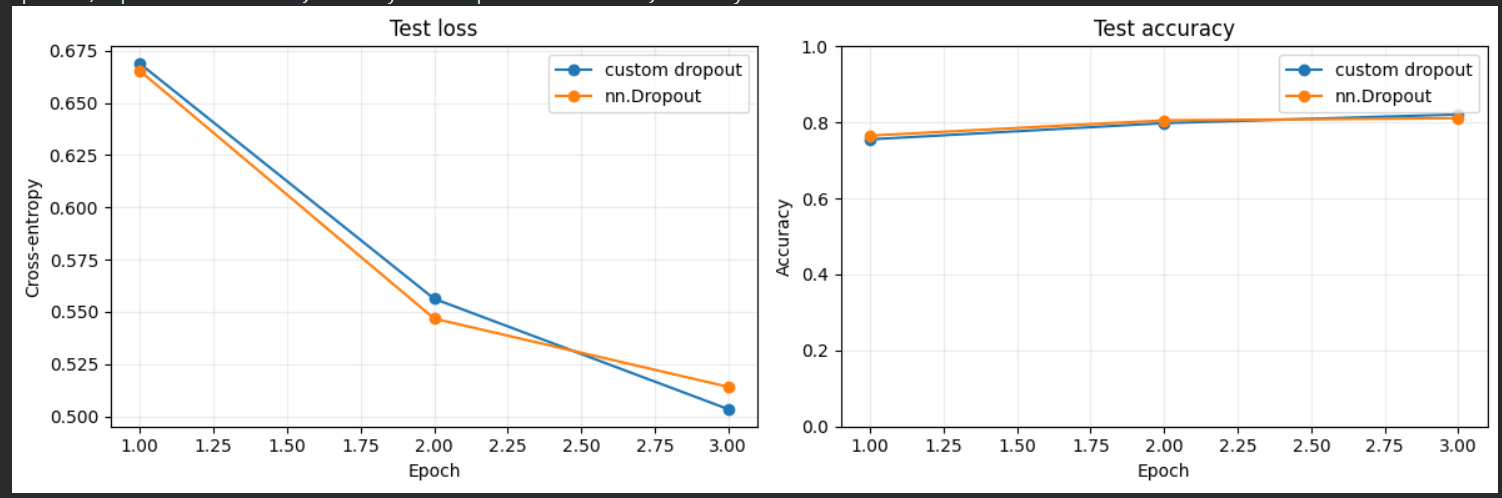

This is showing dropouts set to zero with 20 epochs

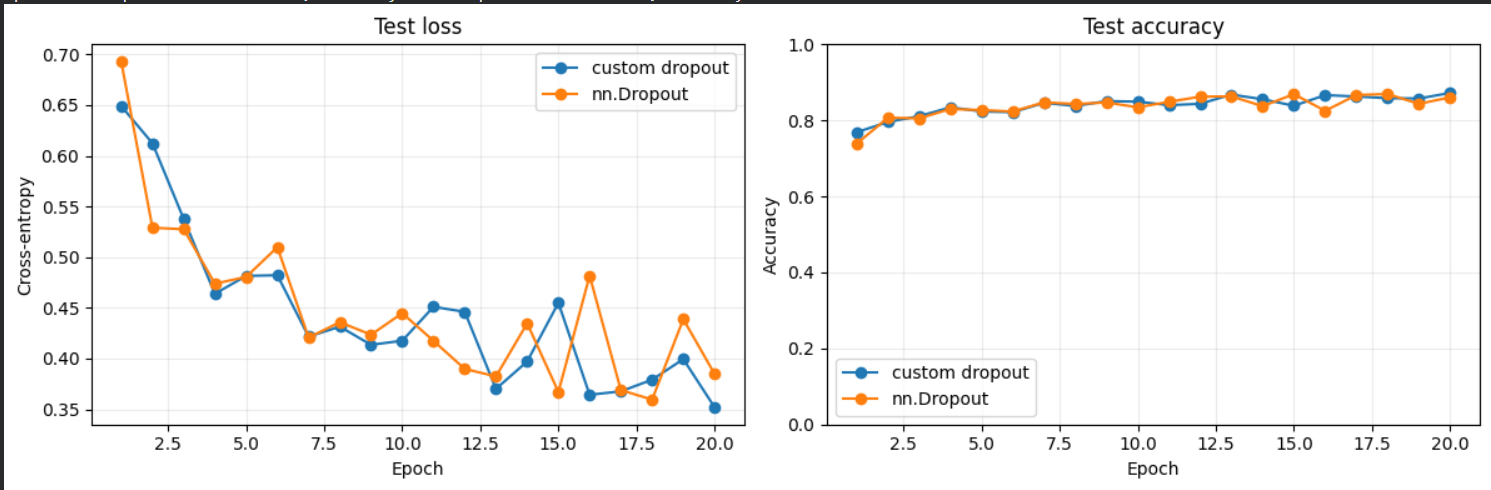

#### 3. Measure the variance of hidden activations with and without dropout. How does it change during training?

**With dropout set to zero, Results below**
_____________________________________________________  
Epoch  1/3  
Before dropout: 0.2770  
After dropout:  0.2753  
Epoch  2/3  
Before dropout: 0.2517  
After dropout:  0.2574  
Epoch  3/3  
Before dropout: 0.2148  
After dropout:  0.2151  

    
**With dropout set to (0.5, 0.2), Results below**  
_____________________________________________________
Epoch  1/3  
Before dropout: 0.1797  
After dropout:  0.4592  
Epoch  2/3  
Before dropout: 0.1425  
After dropout:  0.3629  
Epoch  3/3  
Before dropout: 0.1156  
After dropout:  0.2825  

#### 4. Compare dropout with weight decay, both separately and together.

In [59]:
experiments = {
    "Baseline": (0.0, 0.0, 0.0),
    "Dropout": (0.2, 0.5, 0.0),
    "Weight Decay": (0.0, 0.0, 0.001),
    "Both": (0.2, 0.5, 0.001),
}

results = {}

for name, (d1, d2, wd) in experiments.items():
    print(f"\nExperiment: {name}")

    torch.manual_seed(42)

    model = DropoutMLP(dropout_1=d1, dropout_2=d2)

    results[name] = train_model(
        model,
        train_loader,
        test_loader,
        epochs=10,
        lr=0.1,
        weight_decay=wd
    )


Experiment: Baseline
Epoch  1/10 | train loss 1.0087, accuracy 65.77% | test loss 0.7586, accuracy 73.05%
Epoch  2/10 | train loss 0.5763, accuracy 79.40% | test loss 0.5318, accuracy 81.15%
Epoch  3/10 | train loss 0.4997, accuracy 82.30% | test loss 0.6251, accuracy 76.64%
Epoch  4/10 | train loss 0.4515, accuracy 84.06% | test loss 0.4798, accuracy 82.92%
Epoch  5/10 | train loss 0.4260, accuracy 84.86% | test loss 0.4599, accuracy 83.57%
Epoch  6/10 | train loss 0.4054, accuracy 85.39% | test loss 0.4412, accuracy 84.10%
Epoch  7/10 | train loss 0.3891, accuracy 86.08% | test loss 0.4197, accuracy 84.98%
Epoch  8/10 | train loss 0.3746, accuracy 86.49% | test loss 0.4950, accuracy 82.54%
Epoch  9/10 | train loss 0.3614, accuracy 86.95% | test loss 0.5205, accuracy 81.75%
Epoch 10/10 | train loss 0.3534, accuracy 87.29% | test loss 0.3997, accuracy 85.59%

Experiment: Dropout
Epoch  1/10 | train loss 1.0896, accuracy 60.88% | test loss 0.7033, accuracy 74.51%
Epoch  2/10 | train lo

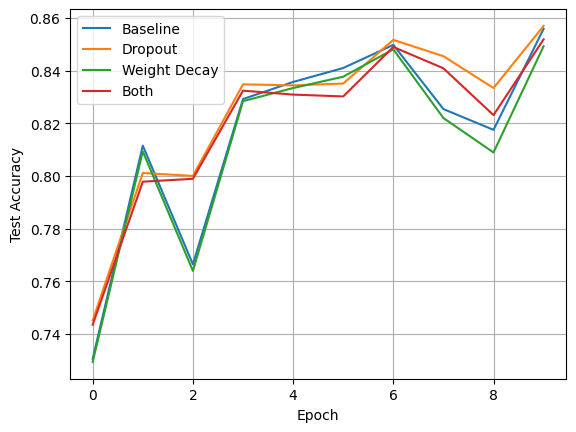

In [60]:
for name, history in results.items():
    plt.plot(history["test_accuracy"], label=name)

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy")
plt.legend()
plt.grid()
plt.show()

#### 5. What might happen if dropout were applied to weights instead of activations?

Dropout applied on activation functions
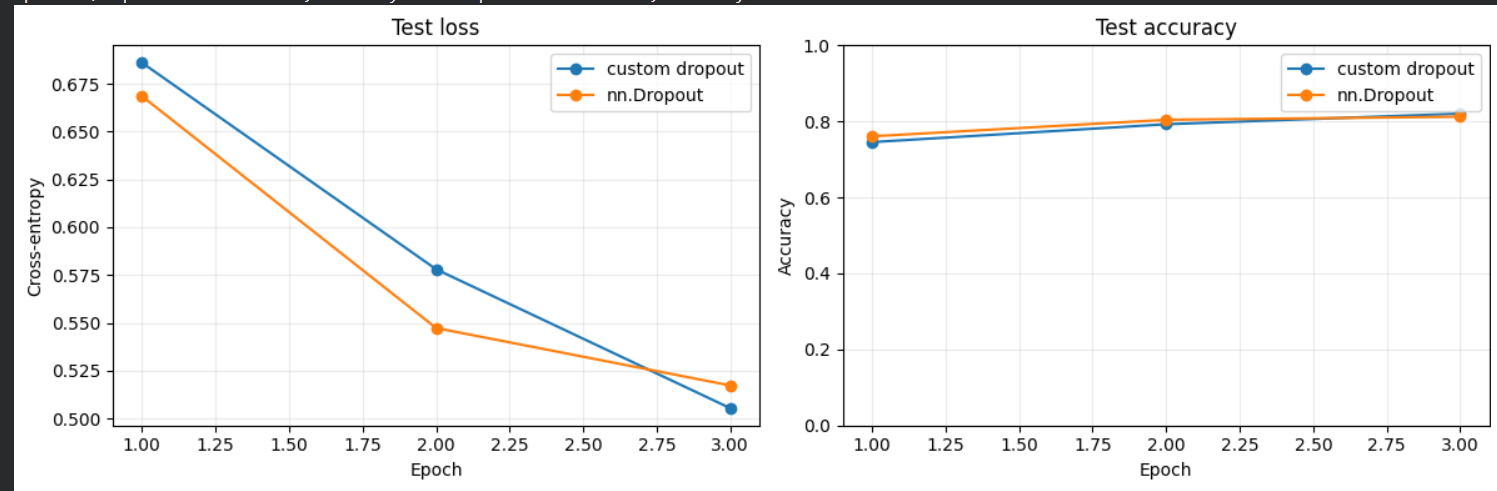

Dropout applied on weights (DropConnect)

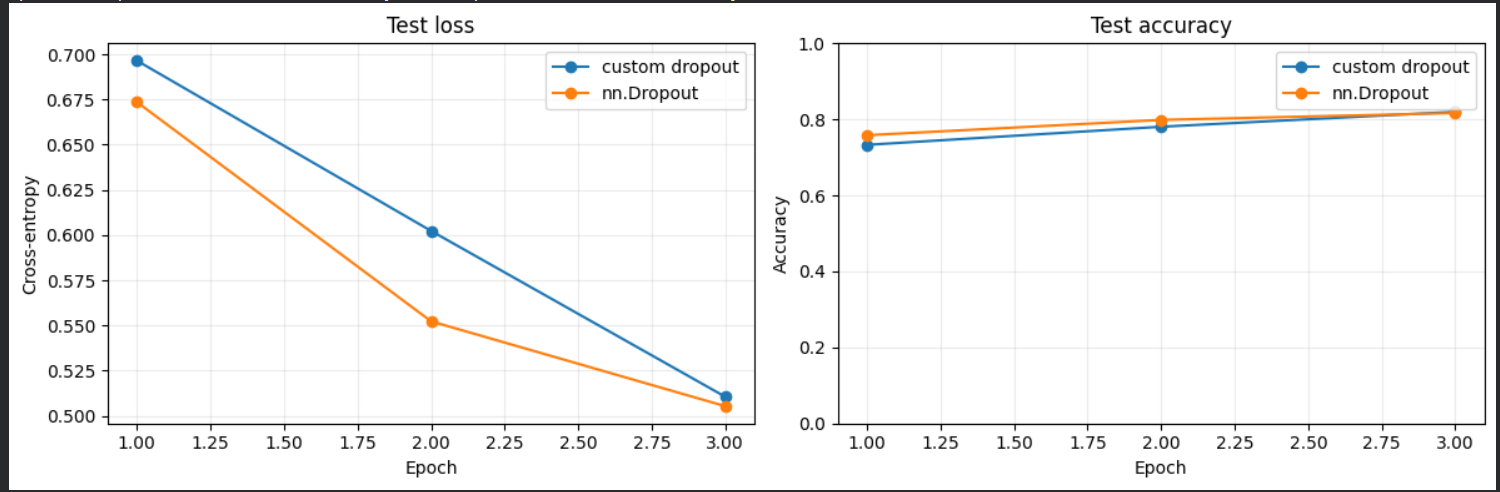